# DSCI 552 Homework 4
**Name:** Yang Zhao  
**USC NetID:** yzhao528  
**Instructor:** Mohammad Reza Rajati

## 2. Time Series Classification Part 2: Binary and Multiclass Classification
This notebook reuses HW3's data cleaning and feature extraction but does not repeat its Part 1 answers. It reads the original recordings so each time series can be split into new contiguous segments. The HW3 code and feature values were checked against [my HW3 repository](https://github.com/jay-zhao1/DSCI552-HW3).

The required filenames define the split. There are 69 training recordings and 19 test recordings. No test observations are used to select features, hyperparameters, or thresholds. `sitting/dataset8.csv` has 479 observations because timestamp 13,500 ms is absent in the original ZIP; its observed values are retained. One whitespace-delimited file and two extra trailing commas are handled as in HW3. Channel order is avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23, var_rss23.

Feature names such as `mean_s1_p2` mean the mean of original channel 1, segment 2. Each of l segments contributes seven statistics for each of six channels, so the matrix has 88 rows and 42l feature columns. `np.array_split` preserves order and uses all observations, with lengths differing by at most one. Standard deviation uses ddof=1, and quartiles use linear interpolation. Splitting changes columns, not the number of recordings.

In [1]:
from pathlib import Path
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.optimize import linprog, minimize
from scipy.stats import norm, chi2
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, label_binarize
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

SEED = 552
DATA = Path('data/AReM')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
# scikit-learn 1.8 emits this compatibility message for the intended C=np.inf fit.
warnings.filterwarnings('ignore', message='Setting penalty=None will ignore the C and l1_ratio parameters', category=UserWarning)
summary = {}

# Reuse HW3's delimiter cleanup and preserve the recording with one missing row.
files = sorted(DATA.glob('*/*.csv'), key=lambda p: (p.parent.name, int(p.stem[7:])))
recordings, rows, audit_rows = [], [], []
for path in files:
    values = []
    spaces = trailing = 0
    for line_no, line in enumerate(path.read_text().splitlines(), 1):
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        spaces += int(',' not in line)
        if line.endswith(','):
            trailing += 1
            line = line[:-1]
        fields = re.split(r'[,\s]+', line)
        if len(fields) != 7:
            raise ValueError(f'{path}:{line_no}: expected seven fields')
        values.append([float(v) for v in fields])
    values = np.asarray(values)
    times = values[:, 0]
    assert np.isfinite(values).all() and (np.diff(times) > 0).all()
    expected_times = np.arange(0, 120000, 250)
    assert np.isin(times, expected_times).all()
    missing = np.setdiff1d(expected_times, times).astype(int)
    activity, number = path.parent.name, int(path.stem[7:])
    cutoff = 2 if activity in ['bending1', 'bending2'] else 3
    rows.append(dict(activity=activity, file=path.name, dataset_number=number,
                     split='test' if number <= cutoff else 'train', n_rows=len(values)))
    audit_rows.append(dict(activity=activity, file=path.name, n_rows=len(values),
                           whitespace_rows=spaces, trailing_commas=trailing,
                           missing_timestamps=','.join(map(str, missing)) or 'none'))
    recordings.append(values[:, 1:])
metadata = pd.DataFrame(rows)
audit = pd.DataFrame(audit_rows)
train = metadata.split.eq('train').to_numpy()
test = ~train
y_binary = metadata.activity.str.startswith('bending').astype(int).to_numpy()
y_train, y_test = y_binary[train], y_binary[test]
y_multi = metadata.activity.to_numpy()
y_multi_train, y_multi_test = y_multi[train], y_multi[test]
classes = np.unique(y_multi_train)
assert len(recordings) == 88 and (train.sum(), test.sum()) == (69, 19)
assert audit.n_rows.value_counts().to_dict() == {480: 87, 479: 1}
assert audit.loc[audit.n_rows.eq(479), ['activity','file','missing_timestamps']].values.tolist() == [['sitting','dataset8.csv','13500']]
for activity, group in metadata.groupby('activity'):
    required = {1,2} if activity.startswith('bending') else {1,2,3}
    assert set(group.loc[group.split.eq('test'), 'dataset_number']) == required
metadata.to_csv(RESULTS/'split_manifest.csv', index=False)
audit.to_csv(RESULTS/'data_audit.csv', index=False)
counts = pd.crosstab(metadata.activity, metadata.split).reindex(columns=['train','test'])
display(counts)
display(audit[(audit.whitespace_rows > 0) | (audit.trailing_commas > 0) | (audit.n_rows != 480)])
print(f'88 recordings: 69 train / 19 test; binary train counts: other={sum(y_train==0)}, bending={sum(y_train==1)}.')

# np.array_split gives consecutive pieces whose lengths differ by at most one.
def extract_features(l):
    feature_rows = []
    for recording in recordings:
        row = {}
        pieces = np.array_split(recording, l, axis=0)
        assert sum(len(piece) for piece in pieces) == len(recording)
        assert max(map(len,pieces)) - min(map(len,pieces)) <= 1
        for part, piece in enumerate(pieces, 1):
            for channel in range(1, 7):
                x = piece[:, channel-1]
                stats = [x.min(), x.max(), x.mean(), np.median(x), x.std(ddof=1),
                         np.quantile(x,.25), np.quantile(x,.75)]
                for kind, value in zip(['min','max','mean','median','std','q1','q3'], stats):
                    row[f'{kind}_s{channel}_p{part}'] = value
        feature_rows.append(row)
    frame = pd.DataFrame(feature_rows)
    assert frame.shape == (88, 42*l) and np.isfinite(frame.to_numpy()).all()
    return frame

features = {l: extract_features(l) for l in range(1,21)}
features[1].to_csv(RESULTS/'features_l1.csv',index=False)
# Channel-major HW3 columns and the l=1 HW4 columns describe the same values.
hw3_names = [f'{t}_{j}' if t in ['q1','q3'] else f'{t}{j}' for j in range(1,7)
             for t in ['min','max','mean','median','std','q1','q3']]
reference = pd.read_csv('data/hw3_features_reference.csv')
np.testing.assert_allclose(features[1],reference[hw3_names],rtol=1e-12,atol=1e-12)
dimensions = pd.DataFrame({'l':range(1,21), 'instances':88,
                           'subseries':[6*l for l in range(1,21)],
                           'features':[42*l for l in range(1,21)]})
dimensions.to_csv(RESULTS/'feature_dimensions.csv',index=False)
display(dimensions)
summary['data'] = {'total':88,'train':69,'test':19,'train_bending':int(y_train.sum()),
                   'train_other':int(sum(y_train==0)), 'test_bending':int(y_test.sum()),'test_other':int(sum(y_test==0))}

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


,activity,file,n_rows,whitespace_rows,trailing_commas,missing_timestamps
10,bending2,dataset4.csv,480,480,0,none
21,cycling,dataset9.csv,480,0,1,none
26,cycling,dataset14.csv,480,0,1,none
50,sitting,dataset8.csv,479,0,0,13500


88 recordings: 69 train / 19 test; binary train counts: other=60, bending=9.


,l,instances,subseries,features
0,1,88,6,42
1,2,88,12,84
2,3,88,18,126
3,4,88,24,168
4,5,88,30,210
5,6,88,36,252
6,7,88,42,294
7,8,88,48,336
8,9,88,54,378
9,10,88,60,420


### 2(a) Binary classification using logistic regression
#### 2(a)(i) Scatter plots before splitting
Bending1 and bending2 are class 1 (bending); the other five activities are class 0 (other). These scatter matrices use only training data and the HW3-selected **mean, standard deviation, and maximum** from original channels 1, 2, and 6. Each off-diagonal panel is a pairwise scatter plot. The diagonal repeats a feature against itself.

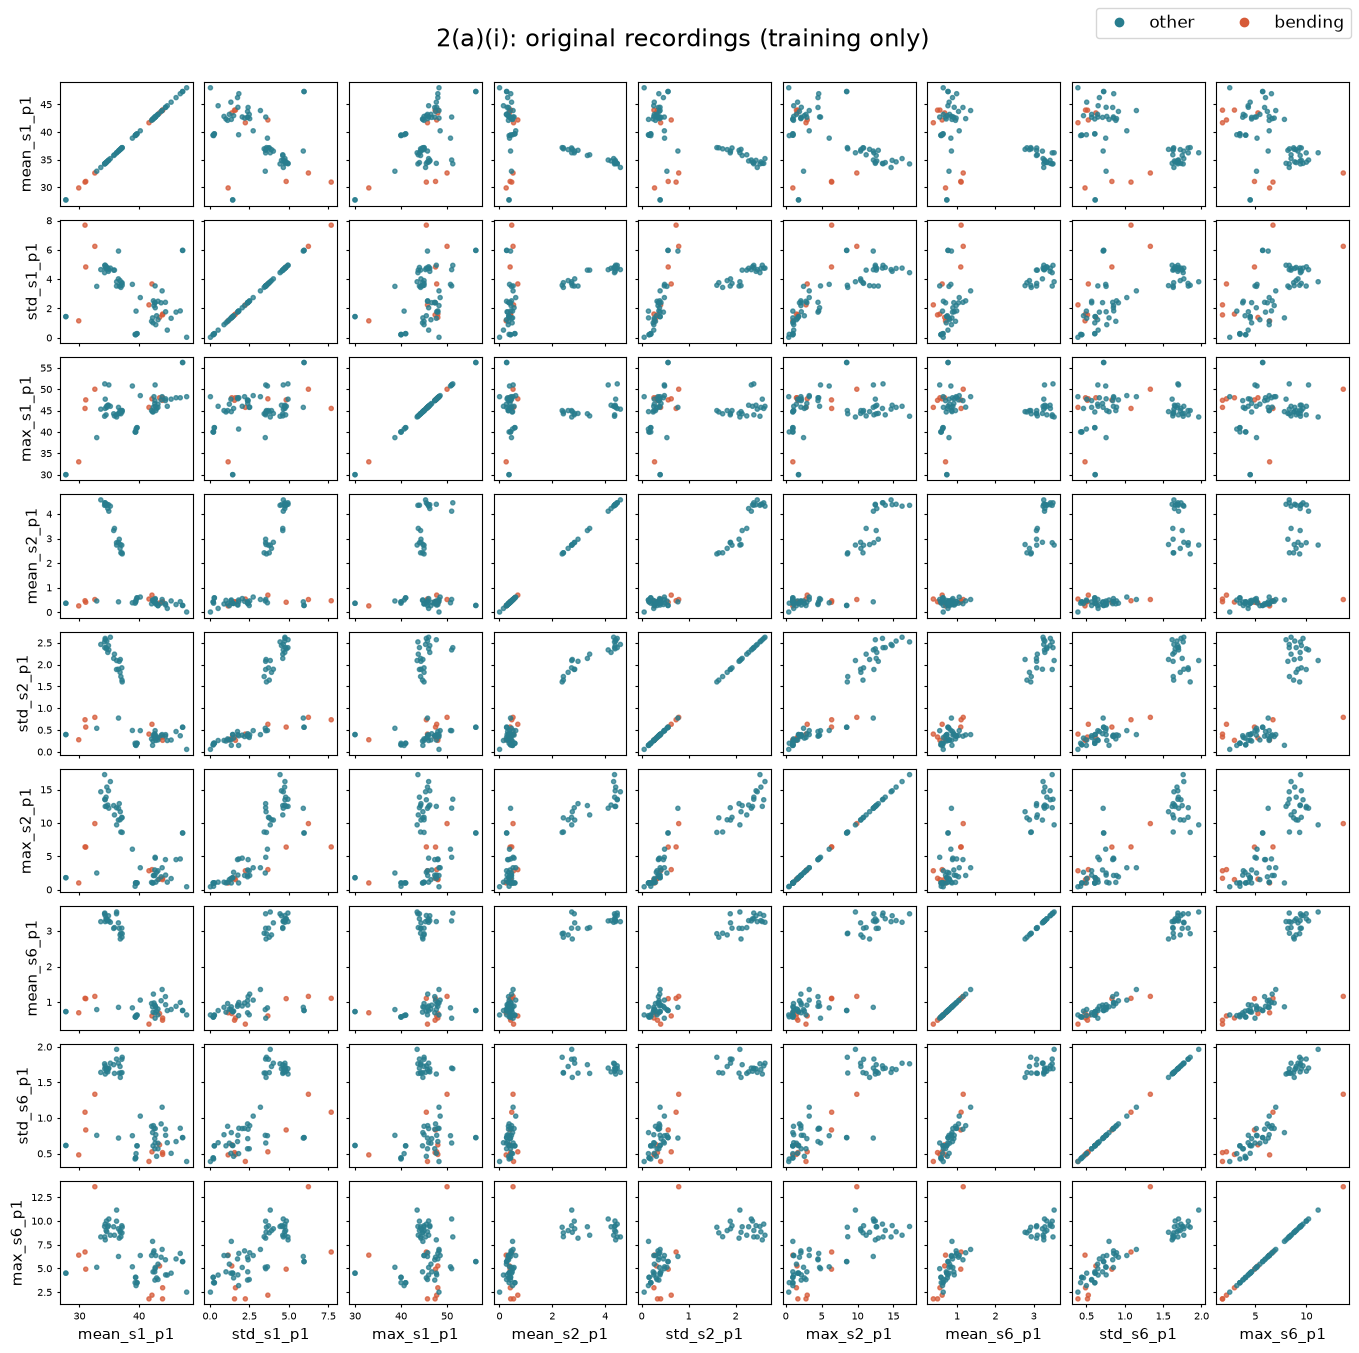

,feature,class,min,max,mean
0,mean_s1_p1,other,27.7164,48.0042,39.1945
1,mean_s1_p1,bending,29.8819,43.9691,37.7446
2,std_s2_p1,other,0.0551,2.6255,1.0848
3,std_s2_p1,bending,0.2631,0.7900,0.4801
4,max_s6_p1,other,2.5000,11.1500,6.7038
5,max_s6_p1,bending,1.7900,13.6100,5.0711


In [2]:
# Full scatter matrices: nine selected features per segment.
def scatter_matrix(left, right, title, filename):
    n = len(left.columns)
    fig, axes = plt.subplots(n, n, figsize=(13.5,13.5))
    colors = np.where(y_train == 1, '#d65a38', '#287d8e')
    for i in range(n):
        for j in range(n):
            ax = axes[i,j]
            ax.scatter(right.iloc[:,j], left.iloc[:,i], c=colors, s=9, alpha=.75)
            ax.tick_params(labelsize=7, length=2)
            if i == n-1:
                ax.set_xlabel(right.columns[j],fontsize=11)
            else:
                ax.set_xticklabels([])
            if j == 0:
                ax.set_ylabel(left.columns[i],fontsize=11)
            else:
                ax.set_yticklabels([])
    from matplotlib.lines import Line2D
    handles = [Line2D([0],[0],marker='o',linestyle='',color=c,label=label)
               for c,label in [('#287d8e','other'),('#d65a38','bending')]]
    fig.legend(handles=handles,loc='upper right',ncol=2,fontsize=12)
    fig.suptitle(title,fontsize=17)
    fig.tight_layout(rect=(0,0,1,.97),pad=.6)
    fig.savefig(RESULTS/filename,dpi=150)
    plt.show()
    plt.close(fig)

plot_cols = lambda part: [f'{kind}_s{channel}_p{part}' for channel in [1,2,6]
                          for kind in ['mean','std','max']]
original = features[1].loc[train, plot_cols(1)]
scatter_matrix(original, original, '2(a)(i): original recordings (training only)', 'scatter_original.png')
# This range table supports the observations below the plots.
ranges=[]
for name in ['mean_s1_p1','std_s2_p1','max_s6_p1']:
    z=features[1].loc[train,name].to_numpy()
    for label,value in [('other',0),('bending',1)]:
        group=z[y_train==value]
        ranges.append({'feature':name,'class':label,'min':group.min(),'max':group.max(),'mean':group.mean()})
scatter_ranges=pd.DataFrame(ranges)
scatter_ranges.to_csv(RESULTS/'scatter_ranges.csv',index=False)
display(scatter_ranges)

There is substantial overlap in mean channel 1: bending ranges from 29.8819 to 43.9691, within the other range 27.7164 to 48.0042. Bending has smaller average std channel 2 (0.4801 versus 1.0848), but those ranges overlap too. Max channel 6 also overlaps. Some pairwise combinations put bending in a relatively low-variation region, but these nine features do not give a clean one-dimensional cutoff. This supports comparing combinations with training-only CV rather than deciding from one plot.

#### 2(a)(ii) Split each series into two parts
Each recording now has 12 subseries, while the training set still has 69 recordings. The first two matrices show the nine requested features for each half; the third shows all cross-half pairs. Together they include every pair among the 18 features from channels 1, 2, and 6. The transposed cross block would repeat the same pairs.

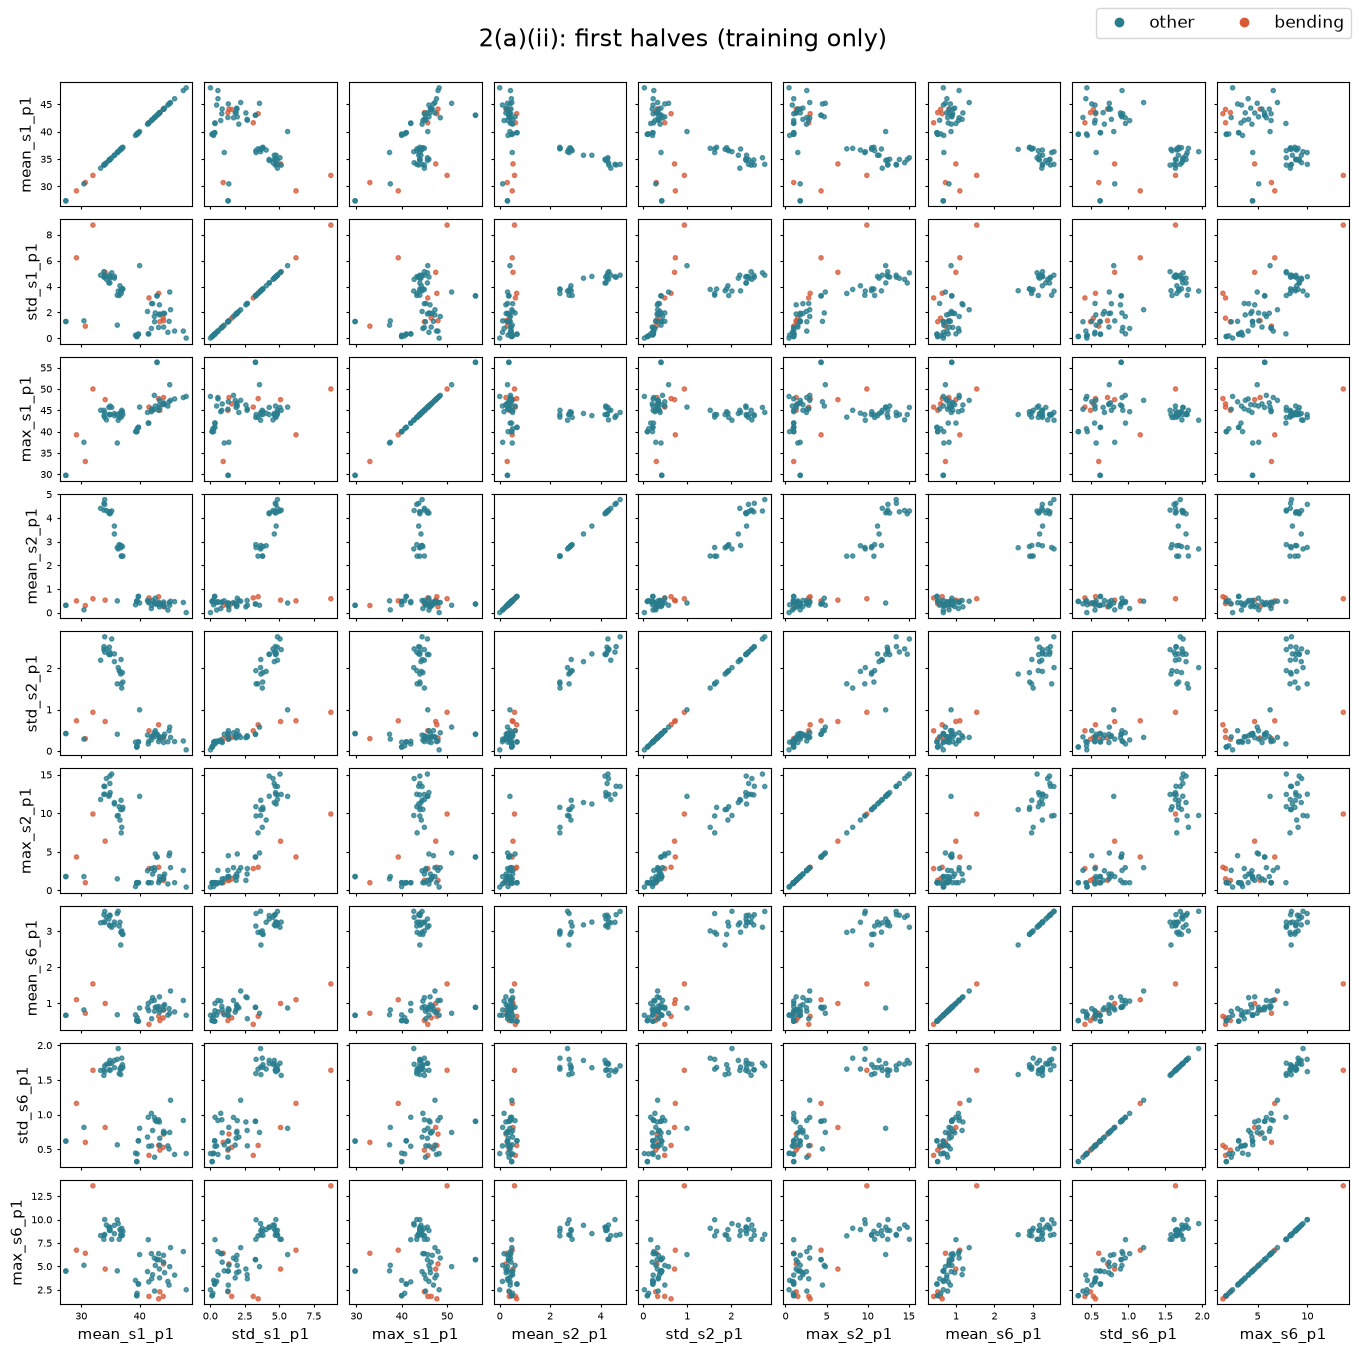

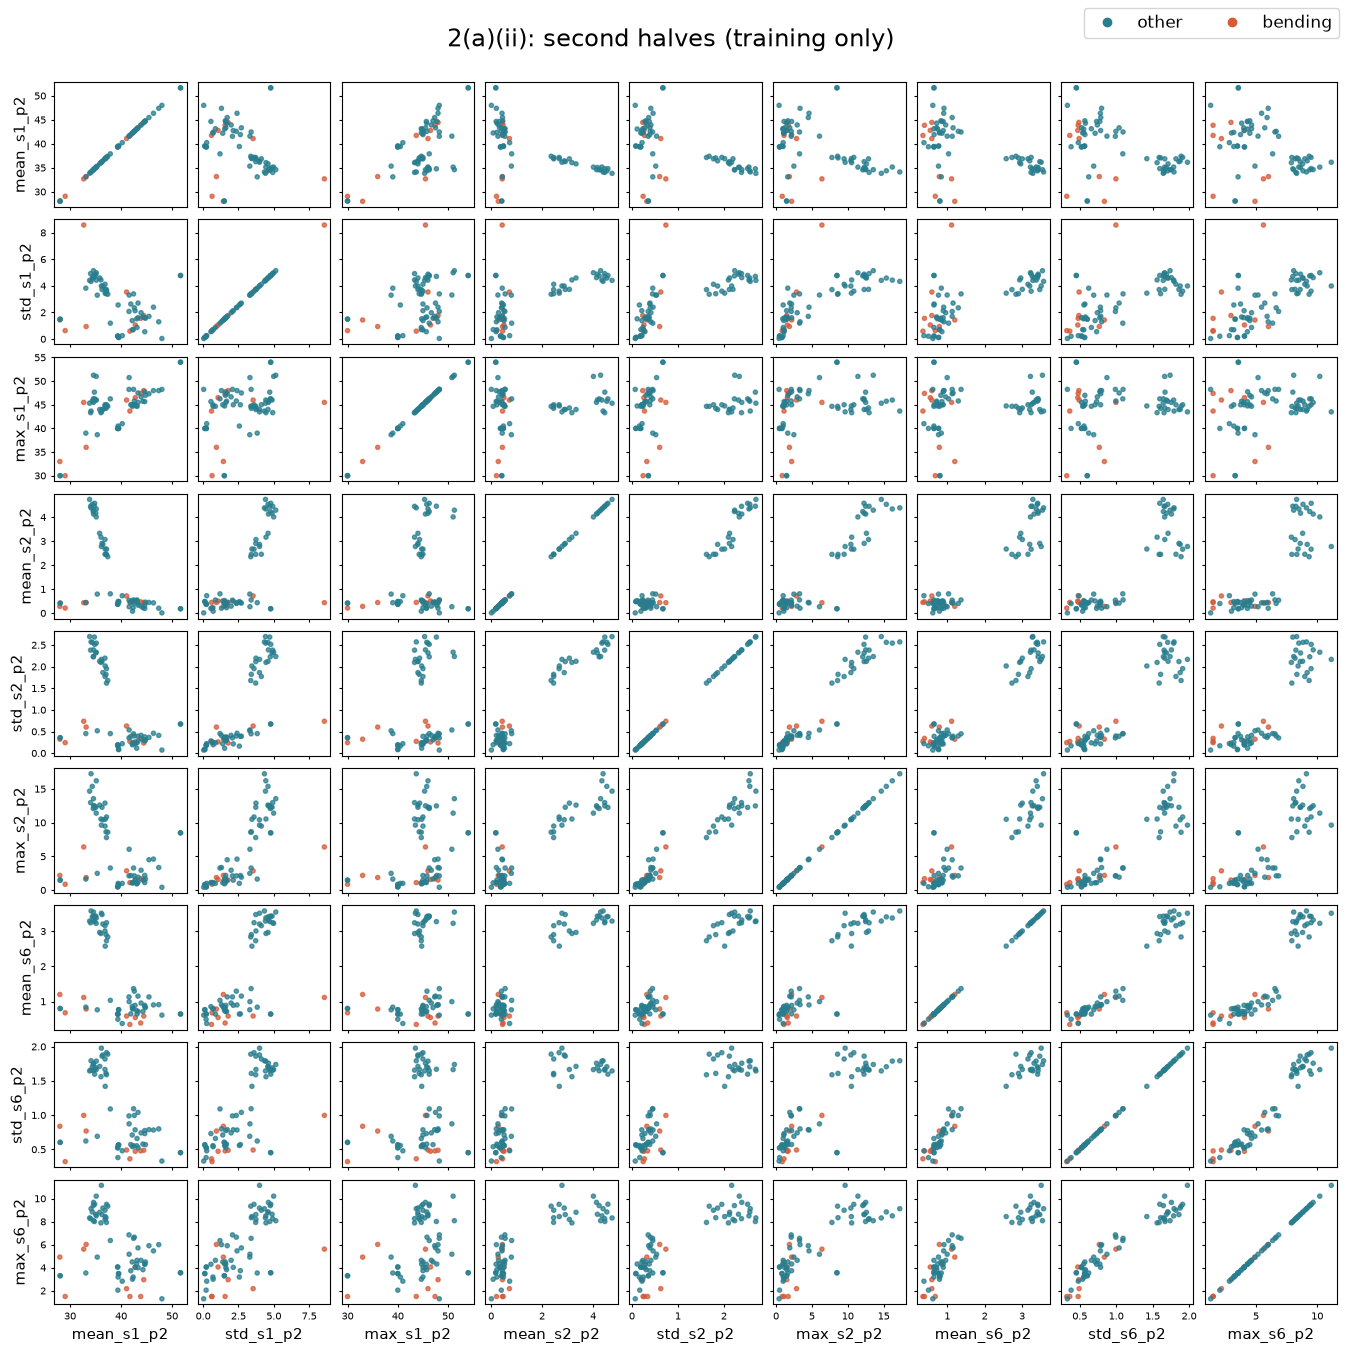

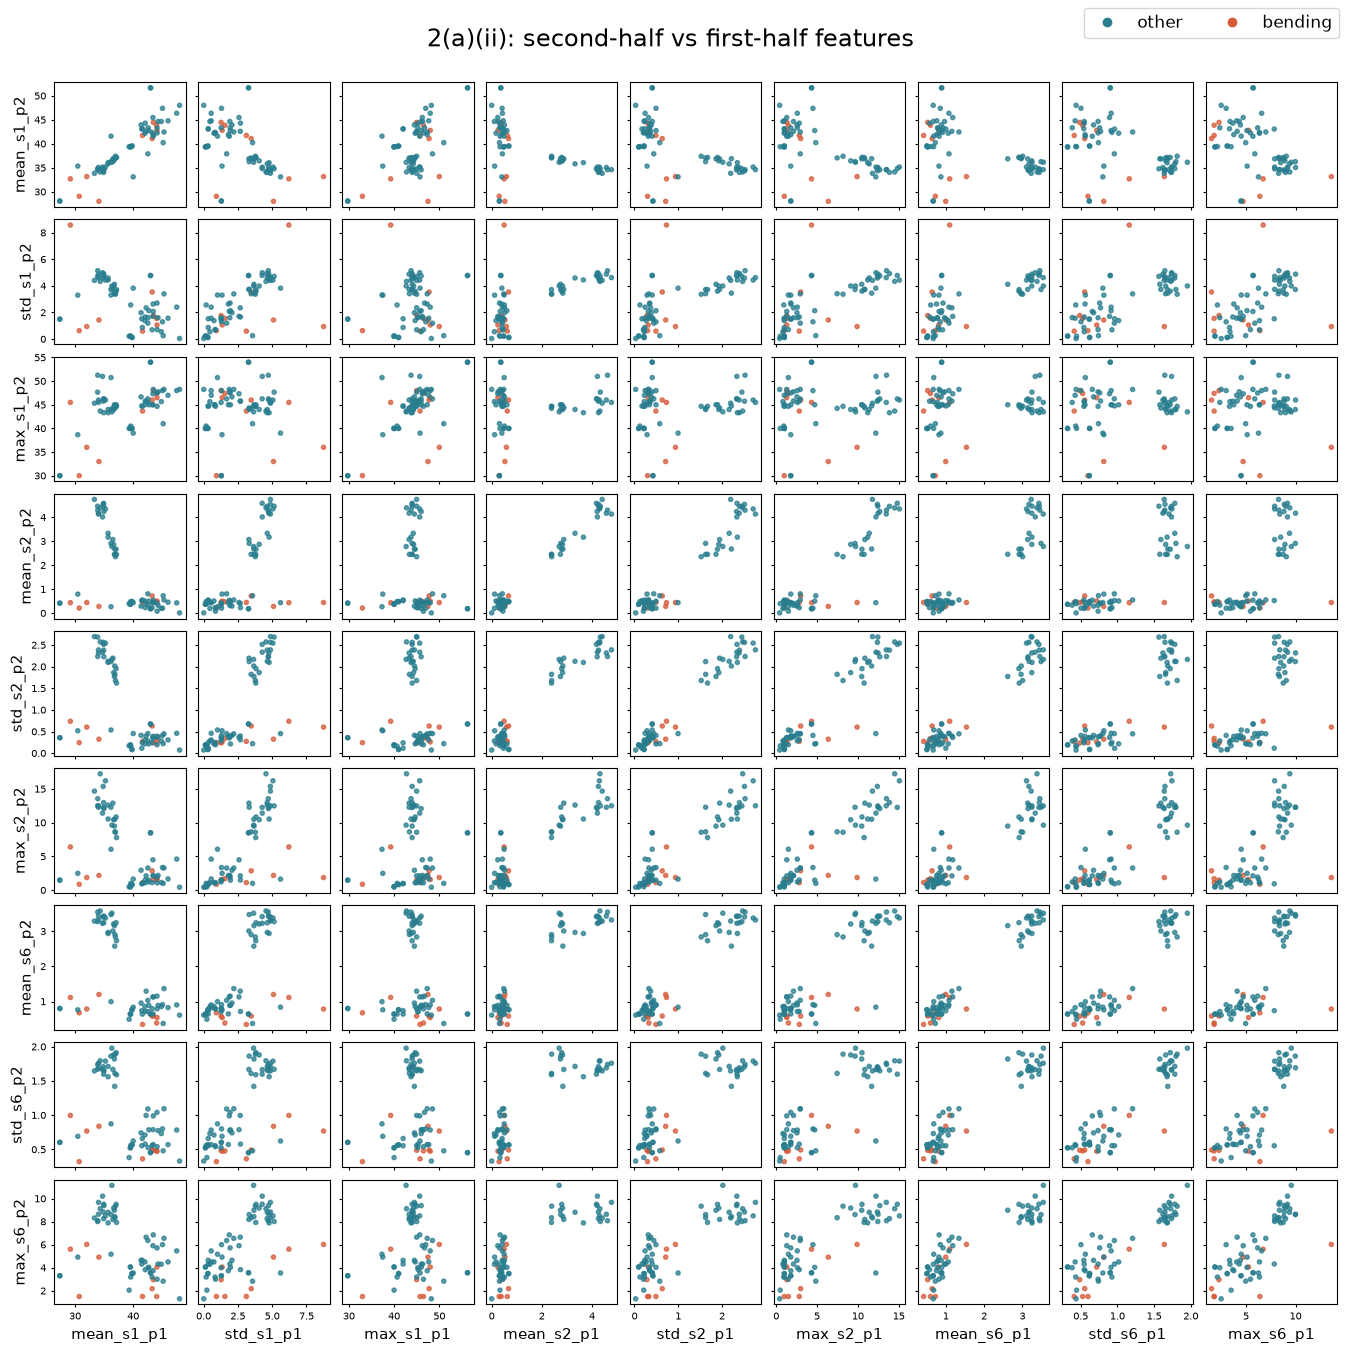

Two segments: 69 training instances, 12 subseries, 84 total features; 18 features shown across these blocks.


In [3]:
first = features[2].loc[train,plot_cols(1)]
second = features[2].loc[train,plot_cols(2)]
scatter_matrix(first,first,'2(a)(ii): first halves (training only)','scatter_first_half.png')
scatter_matrix(second,second,'2(a)(ii): second halves (training only)','scatter_second_half.png')
scatter_matrix(second,first,'2(a)(ii): second-half vs first-half features','scatter_cross_halves.png')
print('Two segments: 69 training instances, 12 subseries, 84 total features; 18 features shown across these blocks.')

Splitting can reveal changes within a recording, but the first- and second-half plots keep the broad activity pattern seen in the original recordings. There is no completely new, clean separation of every bending point from every other point across all panels. Some coordinates move and their spread changes because each statistic now describes a shorter interval. The halves are measurements from the same recording, not 138 independent training examples.

#### 2(a)(iii) RFE and five-fold cross-validation
I use **recursive feature elimination (RFE)**, the assignment's alternative to p-value pruning. RFE repeatedly removes features with the smallest squared logistic coefficients after standardization. Its ranks are selection ranks, not p-values.

For every l from 1 to 20, the candidate counts are p = 1, 2, 3, 4, 5, 6, 8, 10, 12, 18, 24, 36, 54, 84, keeping only counts no larger than 42l. RFE removes 25% of the original feature count per step until it reaches the requested p. The final ordinary model is unpenalized (`C=np.inf`), with tolerance 1e-6 and at most 2,000 iterations. This searches a stated p grid, rather than claiming exhaustive optimization over every possible feature subset or count.

I use five stratified folds with shuffle=True and seed 552. There are only nine bending training cases; stratification keeps bending examples in both the fitting and validation parts. **Correct:** in each fold, fit scaling, RFE, and logistic regression only on that fold's fitting data, then score its untouched validation data. The pipeline enforces this. Segmentation and summary formulas have no fitted parameters and may be computed beforehand. **Wrong:** choose features or fit a scaler on all 69 recordings before CV; then validation observations influence the fitted representation, giving optimistic scores. Test data must never select l or p.

The objective is mean fold accuracy, as specified in the assignment. Balanced accuracy is also reported at evaluation because the classes are imbalanced. Ties prefer smaller l, then smaller p (or smaller C for regularized models). The selected CV score is a tuning score, not an unbiased estimate after model selection.

In [4]:
cv_binary = list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(np.zeros(len(y_train)),y_train))
# One validation fold lacks bending2 (four training cases), but all fit folds retain it.
with warnings.catch_warnings(record=True) as split_messages:
    warnings.simplefilter('always', UserWarning)
    cv_multi = list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(np.zeros(len(y_multi_train)),y_multi_train))
multi_folds = []
for i, (fit_idx, valid_idx) in enumerate(cv_multi, 1):
    assert len(np.unique(y_multi_train[fit_idx])) == 7
    multi_folds.append({'fold': i, 'fit_bending2': int(sum(y_multi_train[fit_idx]=='bending2')),
                        'valid_bending2': int(sum(y_multi_train[valid_idx]=='bending2'))})
pd.DataFrame(multi_folds).to_csv(RESULTS/'multiclass_cv_folds.csv', index=False)
fold_counts=[]
for i,(fit_idx,valid_idx) in enumerate(cv_binary,1):
    fold_counts.append({'fold':i,'fit_bending':int(y_train[fit_idx].sum()),
                        'valid_bending':int(y_train[valid_idx].sum()),
                        'fit_other':int(sum(y_train[fit_idx]==0)), 'valid_other':int(sum(y_train[valid_idx]==0))})
pd.DataFrame(fold_counts).to_csv(RESULTS/'binary_cv_folds.csv',index=False)
display(pd.DataFrame(fold_counts))

# Shared search loop; every fitted preprocessing/selection step stays in its pipeline.
def search_segments(pipeline, param_grid, labels, folds, name):
    all_rows = []
    warning_count = 0
    for l in range(1,21):
        grid = param_grid(features[l].shape[1]) if callable(param_grid) else param_grid
        search = GridSearchCV(pipeline,grid,scoring='accuracy',cv=folds,
                              refit=False,error_score='raise',n_jobs=1)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            search.fit(features[l].loc[train],labels)
        warning_count += sum(issubclass(w.category,ConvergenceWarning) for w in caught)
        for i,params in enumerate(search.cv_results_['params']):
            row = {'l':l,**params,'mean_cv':search.cv_results_['mean_test_score'][i],
                   'std_cv':search.cv_results_['std_test_score'][i]}
            row.update({f'fold_{k+1}':search.cv_results_[f'split{k}_test_score'][i] for k in range(len(folds))})
            all_rows.append(row)
    results = pd.DataFrame(all_rows)
    # Ties: fewer segments first, then fewer RFE features / stronger regularization.
    order=['mean_cv','l'] + [c for c in ['select__n_features_to_select','model__C','model__alpha','model__var_smoothing'] if c in results]
    results = results.sort_values(order,ascending=[False]+[True]*(len(order)-1)).reset_index(drop=True)
    results.to_csv(RESULTS/f'{name}_cv.csv',index=False)
    best = results.iloc[0]
    params = {k:best[k] for k in results.columns if '__' in k}
    if 'select__n_features_to_select' in params:
        params['select__n_features_to_select'] = int(params['select__n_features_to_select'])
    fitted = clone(pipeline).set_params(**params)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        fitted.fit(features[int(best.l)].loc[train],labels)
    final_warning = sum(issubclass(w.category,ConvergenceWarning) for w in caught)
    summary[name] = {'l':int(best.l),'params':{k:float(v) for k,v in params.items()},
                     'cv_accuracy':float(best.mean_cv),'cv_std':float(best.std_cv),
                     'cv_convergence_warnings':int(warning_count),'final_convergence_warnings':int(final_warning)}
    display(results.head(10))
    display(Markdown(f"Best **l={int(best.l)}**, parameters `{params}`, CV accuracy **{best.mean_cv:.4f}**. "
                     f"Convergence warnings: {warning_count} during CV; {final_warning} in the final refit."))
    return fitted,results

ordinary = LogisticRegression(C=np.inf,solver='lbfgs',max_iter=2000,tol=1e-6)
rfe_pipeline = Pipeline([('scale',StandardScaler()),
                         ('select',RFE(ordinary,step=.25)),('model',ordinary)])
p_grid = [1,2,3,4,5,6,8,10,12,18,24,36,54,84]
rfe_model,rfe_cv = search_segments(rfe_pipeline,
    lambda d:{'select__n_features_to_select':[p for p in p_grid if p<=d]},
    y_train,cv_binary,'rfe')
l_rfe=summary['rfe']['l']
selected=features[l_rfe].columns[rfe_model.named_steps['select'].support_].tolist()
pd.DataFrame({'feature':selected}).to_csv(RESULTS/'rfe_selected_features.csv',index=False)
print('Selected features:',selected)

,fold,fit_bending,valid_bending,fit_other,valid_other
0,1,7,2,48,12
1,2,7,2,48,12
2,3,7,2,48,12
3,4,7,2,48,12
4,5,8,1,48,12


,l,select__n_features_to_select,mean_cv,std_cv,fold_1,fold_2,fold_3,fold_4,fold_5
0,1,4,0.9857,0.0286,1.0000,1.0000,1.0000,0.9286,1.0000
1,3,3,0.9714,0.0350,1.0000,1.0000,0.9286,0.9286,1.0000
2,9,4,0.9714,0.0350,0.9286,0.9286,1.0000,1.0000,1.0000
3,18,5,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000
4,18,6,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000
5,19,5,0.9714,0.0350,1.0000,0.9286,1.0000,0.9286,1.0000
6,19,6,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000
7,20,10,0.9714,0.0571,1.0000,0.8571,1.0000,1.0000,1.0000
8,20,12,0.9714,0.0571,1.0000,1.0000,0.8571,1.0000,1.0000
9,1,5,0.9703,0.0364,1.0000,1.0000,1.0000,0.9286,0.9231


Best **l=1**, parameters `{'select__n_features_to_select': 4}`, CV accuracy **0.9857**. Convergence warnings: 0 during CV; 0 in the final refit.

Selected features: ['q3_s1_p1', 'max_s2_p1', 'min_s5_p1', 'max_s5_p1']


#### 2(a)(iv) Training confusion matrix, ROC, coefficients, and inference
The final model is refitted on all training recordings at the selected (l,p). Confusion-matrix rows are true labels and columns are predicted labels, ordered other, bending. The decision threshold is 0.5; bending is the ROC positive class. The coefficient table gives both standardized and original-feature units, including the intercept.

For a finite, full-rank maximum-likelihood fit, the Wald covariance estimate is $(A^TWA)^{-1}$, where A includes the intercept and $W_{ii}=\hat p_i(1-\hat p_i)$. The two-sided nominal p-value is $2\Phi(-|\hat\beta_j/SE_j|)$. A pseudoinverse is used only to compute a numerical diagnostic if the information is ill-conditioned. It does not rescue invalid inference. A linear program separately checks complete or quasi-separation. When no finite ordinary MLE exists, the nominal numbers are marked invalid rather than presented as valid significance tests.

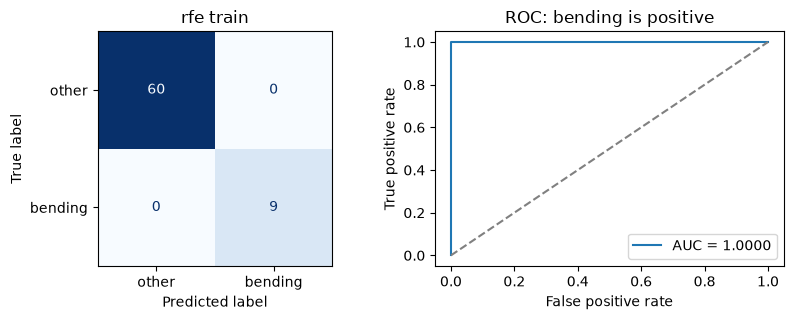

,accuracy,balanced_accuracy,auc
0,1.0000,1.0000,1.0000


,term,beta_standardized,beta_raw,nominal_wald_p,p_value_valid
0,intercept,-34.4095,-11.6817,0.9379,False
1,q3_s1_p1,-13.4217,-2.8263,0.9870,False
2,max_s2_p1,-8.1463,-1.5941,0.9919,False
3,min_s5_p1,17.1474,3.2173,0.9580,False
4,max_s5_p1,20.4062,3.7719,0.9547,False


Complete separation: **True**; quasi-separation: **False**; LP margin 0.322438; information rank 5/5. The coefficient table includes nominal Wald calculations, not RFE rankings. When separation occurs, there is no finite ordinary MLE and these nominal p-values are invalid. Even without separation, feature selection makes unadjusted Wald inference exploratory.

In [5]:
# Class 1 is bending; confusion-matrix rows are true classes, columns predicted.
def binary_evaluate(probability, labels, name):
    predicted=(probability>.5).astype(int)
    cm=confusion_matrix(labels,predicted,labels=[0,1])
    result={'accuracy':float(accuracy_score(labels,predicted)),
            'balanced_accuracy':float(balanced_accuracy_score(labels,predicted)),
            'auc':float(roc_auc_score(labels,probability)), 'confusion_matrix':cm.tolist()}
    pd.DataFrame({'true':labels,'prob_bending':probability,'predicted':predicted}).to_csv(RESULTS/f'{name}_predictions.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(8.4,3.3))
    ConfusionMatrixDisplay(cm,display_labels=['other','bending']).plot(ax=axes[0],colorbar=False,cmap='Blues')
    axes[0].set_title(name.replace('_',' '))
    fpr,tpr,_=roc_curve(labels,probability)
    axes[1].plot(fpr,tpr,label=f'AUC = {result["auc"]:.4f}')
    axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC: bending is positive')
    axes[1].legend(loc='lower right')
    fig.tight_layout();fig.savefig(RESULTS/f'{name}.png',dpi=180)
    plt.show();plt.close(fig)
    display(pd.DataFrame([{k:v for k,v in result.items() if k!='confusion_matrix'}]))
    return result

X_rfe=features[l_rfe]
summary['rfe']['train']=binary_evaluate(rfe_model.predict_proba(X_rfe.loc[train])[:,1],y_train,'rfe_train')
# Coefficients describe the numerical unpenalized fit, not automatically a finite MLE.
scaler=rfe_model.named_steps['scale']
mask=rfe_model.named_steps['select'].support_
Z=rfe_model.named_steps['select'].transform(scaler.transform(X_rfe.loc[train]))
A=np.column_stack([np.ones(len(Z)),Z])
beta=np.r_[rfe_model.named_steps['model'].intercept_,rfe_model.named_steps['model'].coef_.ravel()]
prob=expit(A@beta)
information=A.T@((prob*(1-prob))[:,None]*A)
rank=int(np.linalg.matrix_rank(information))
cov=np.linalg.pinv(information)
se=np.sqrt(np.maximum(np.diag(cov),0))
wald_p=2*norm.sf(np.divide(np.abs(beta),se,out=np.full_like(beta,np.inf),where=se>0))
# A positive feasible margin proves complete separation for these selected features.
signed=(2*y_train-1)[:,None]*A
lp=linprog(np.r_[np.zeros(A.shape[1]),-1],A_ub=np.column_stack([-signed,np.ones(len(A))]),
           b_ub=np.zeros(len(A)),bounds=[(-1,1)]*A.shape[1]+[(None,None)],method='highs')
margin=float(lp.x[-1]) if lp.success else np.nan
separated=bool(lp.success and margin>1e-8)
quasi_lp=linprog(-signed.sum(axis=0),A_ub=-signed,b_ub=np.zeros(len(A)),
                 bounds=[(-1,1)]*A.shape[1],method='highs')
quasi=bool(not separated and quasi_lp.success and -quasi_lp.fun>1e-8)
raw_beta=beta[1:]/scaler.scale_[mask]
raw_intercept=beta[0]-np.sum(raw_beta*scaler.mean_[mask])
coef_table=pd.DataFrame({'term':['intercept']+selected,'beta_standardized':beta,
    'beta_raw':np.r_[raw_intercept,raw_beta],'nominal_wald_p':wald_p,
    'p_value_valid':not(separated or quasi or rank<len(beta))})
coef_table.to_csv(RESULTS/'ordinary_coefficients.csv',index=False)
display(coef_table)
summary['inference']={'complete_separation':separated,'quasi_separation':quasi,'lp_margin':margin,
                       'information_rank':rank,'parameters':len(beta),'information_condition':float(np.linalg.cond(information))}
display(Markdown(f"Complete separation: **{separated}**; quasi-separation: **{quasi}**; "
                 f"LP margin {margin:.6f}; information rank {rank}/{len(beta)}. "
                 "The coefficient table includes nominal Wald calculations, not RFE rankings. "
                 "When separation occurs, there is no finite ordinary MLE and these nominal p-values are invalid. "
                 "Even without separation, feature selection makes unadjusted Wald inference exploratory."))

#### 2(a)(v) Test evaluation
Use the same l, scaler, selected columns, and coefficients. There is no refitting on the test set.

The supplied data contain two exact train/test duplicates: cycling/dataset1.csv (test) equals cycling/dataset15.csv (train), and lying/dataset1.csv (test) equals lying/dataset15.csv (train). I retain the required split and all observations; therefore, 100% test accuracy on this split is not a guarantee of performance on fully independent new recordings.

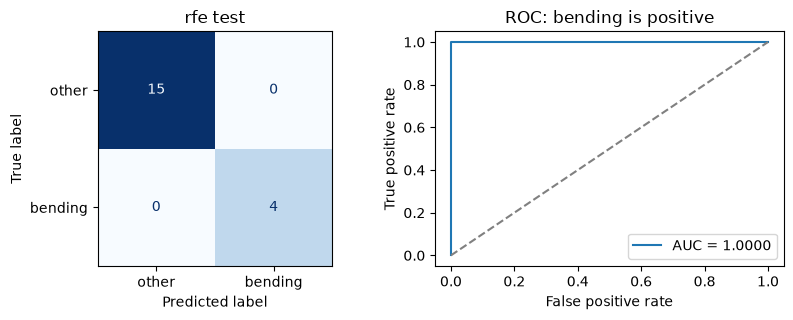

,accuracy,balanced_accuracy,auc
0,1.0000,1.0000,1.0000


Test accuracy is **1.0000**, compared with selected CV accuracy **0.9857**. The test set has only 19 recordings; one changed prediction changes its accuracy by 1/19 = 0.0526. The selected CV maximum can also be optimistic after trying many settings. No parameters are selected from the test result.

,tolerance,iterations,coefficient_norm,max_abs_coefficient,train_accuracy
0,0.0010,9,8.0230,5.5887,1.0000
1,0.0000,21,30.9346,20.4062,1.0000
2,0.0000,31,49.7919,32.4905,1.0000


In [6]:
summary['rfe']['test']=binary_evaluate(rfe_model.predict_proba(X_rfe.loc[test])[:,1],y_test,'rfe_test')
display(Markdown(f"Test accuracy is **{summary['rfe']['test']['accuracy']:.4f}**, compared with selected CV accuracy "
                 f"**{summary['rfe']['cv_accuracy']:.4f}**. The test set has only 19 recordings; one changed prediction "
                 "changes its accuracy by 1/19 = 0.0526. The selected CV maximum can also be optimistic after trying many settings. "
                 "No parameters are selected from the test result."))
stability=[]
for tolerance in [1e-3,1e-6,1e-9]:
    fit=LogisticRegression(C=np.inf,solver='lbfgs',max_iter=4000,tol=tolerance).fit(Z,y_train)
    stability.append({'tolerance':tolerance,'iterations':int(fit.n_iter_[0]),
                       'coefficient_norm':np.linalg.norm(fit.coef_),
                       'max_abs_coefficient':np.abs(fit.coef_).max(),
                       'train_accuracy':fit.score(Z,y_train)})
stability=pd.DataFrame(stability)
stability.to_csv(RESULTS/'ordinary_stability.csv',index=False)
display(stability)

#### 2(a)(vi) Separation and stability
Complete separation means some coefficient vector gives a strictly positive signed margin for every training observation. Quasi-separation allows zero margins with at least one positive margin. The bounded linear programs test these conditions directly. The tolerance table holds the selected feature set fixed and checks how coefficient size changes as the optimizer is asked to fit more precisely. High accuracy alone does not prove separation; a positive LP margin does.

If separation is present, ordinary coefficients can increase without a finite maximum, even if the optimizer reports a stopping condition. The finite coefficients above are numerical predictive fits, not well-defined ordinary MLEs. Early numerical stopping is consistent with the assignment's warning, but does not make their Wald p-values valid. L1 regularization in 2(b) addresses coefficient instability.

To provide meaningful finite-coefficient inference as a separate supplement, a full-rank separated design is also fit with Firth's Jeffreys-information penalty. This is explicitly separate from the unpenalized classifier and RFE selection. Its approximate penalized likelihood-ratio p-values still do not account for feature selection.

For the selected model the LP margin is 0.322438, proving complete separation. As tolerance changes from 1e-3 to 1e-9, the coefficient norm increases from 8.0230 to 49.7919, while training accuracy remains 1.0000. The nominal ordinary p-values therefore cannot support significance claims.

In [7]:
# Separate, bias-reduced inference when ordinary likelihood has no finite maximum.
# This does not replace the ordinary model used for prediction above.
def firth_objective(b):
    p=expit(A@b)
    weights=np.maximum(p*(1-p),1e-12)
    info=A.T@(weights[:,None]*A)
    sign,logdet=np.linalg.slogdet(info)
    if sign<=0:
        return np.inf,np.zeros_like(b)
    inv=np.linalg.inv(info)
    hat=weights*np.sum((A@inv)*A,axis=1)
    loglik=np.sum(y_train*(A@b)-np.logaddexp(0,A@b))
    adjusted_score=A.T@(y_train-p+hat*(.5-p))
    return -loglik-.5*logdet,-adjusted_score

firth_rows=[]
if (separated or quasi) and np.linalg.matrix_rank(A)==A.shape[1]:
    firth=minimize(firth_objective,np.zeros(A.shape[1]),jac=True,method='BFGS',options={'gtol':1e-7,'maxiter':2000})
    full_objective=firth.fun
    for j,term in enumerate(['intercept']+selected):
        keep=np.arange(len(beta))!=j
        def restricted(b):
            expanded=np.zeros(len(beta));expanded[keep]=b
            value,gradient=firth_objective(expanded)
            return value,gradient[keep]
        reduced=minimize(restricted,firth.x[keep],jac=True,method='BFGS',options={'gtol':1e-7,'maxiter':2000})
        lr=max(0.,2*(reduced.fun-full_objective))
        firth_rows.append({'term':term,'firth_beta_standardized':firth.x[j],
                           'penalized_lr':lr,'approx_p_value':chi2.sf(lr,1),
                           'full_gradient_max':np.abs(firth.jac).max(),
                           'restricted_gradient_max':np.abs(reduced.jac).max()})
    firth_table=pd.DataFrame(firth_rows)
    assert np.isfinite(firth_table.iloc[:,1:].to_numpy()).all()
    assert firth_table[['full_gradient_max','restricted_gradient_max']].to_numpy().max()<1e-4
    firth_table.to_csv(RESULTS/'supplementary_firth_inference.csv',index=False)
    display(firth_table)
    display(Markdown("Because the ordinary MLE is separated, these are **supplementary Firth penalized-likelihood** "
                     "results. The penalty is one half log determinant of the Fisher information. Each coefficient is tested "
                     "by fixing it to zero, reoptimizing the others, and comparing twice the penalized log-likelihood difference "
                     "to chi-square(1). These are approximate, conditional-on-selected-features p-values, not ordinary-MLE "
                     "p-values or selection-adjusted significance tests. The predictive classifier remains the unpenalized model."))
    summary['inference']['supplement']='Firth penalized likelihood-ratio tests; approximate and not selection-adjusted'
else:
    display(Markdown('Supplementary Firth fitting is not needed, or the selected design is rank deficient.'))

,term,firth_beta_standardized,penalized_lr,approx_p_value,full_gradient_max,restricted_gradient_max
0,intercept,-3.9337,45.4567,0.0000,0.0000,0.0000
1,q3_s1_p1,-1.2470,2.9263,0.0871,0.0000,0.0000
2,max_s2_p1,-1.1010,1.7479,0.1861,0.0000,0.0000
3,min_s5_p1,1.4934,2.2403,0.1345,0.0000,0.0000
4,max_s5_p1,2.3686,17.8487,0.0000,0.0000,0.0000


Because the ordinary MLE is separated, these are **supplementary Firth penalized-likelihood** results. The penalty is one half log determinant of the Fisher information. Each coefficient is tested by fixing it to zero, reoptimizing the others, and comparing twice the penalized log-likelihood difference to chi-square(1). These are approximate, conditional-on-selected-features p-values, not ordinary-MLE p-values or selection-adjusted significance tests. The predictive classifier remains the unpenalized model.

#### 2(a)(vii) Case-control sampling and prior correction
Class counts, not just accuracy, show the imbalance: the training set contains 60 other and 9 bending recordings. I sample the minority class with replacement to obtain 60 bending and 60 other cases, using only training data and seed 552. The original RFE feature set stays fixed.

With class-conditional sampling, slopes are unchanged in the population model but the intercept reflects the altered class odds. If $\pi$ is the original training prevalence and $\pi_s$ is the sampled prevalence, the corrected intercept is
$$\beta_{0,\mathrm{target}}=\beta_{0,\mathrm{sample}}+\log\frac{\pi}{1-\pi}-\log\frac{\pi_s}{1-\pi_s}.$$
Here the target prior is estimated from the original training set, not from test labels. The correction changes probabilities and possibly the 0.5-threshold confusion matrix, but cannot change ROC ordering or AUC for that fitted score. Under separation, intercept correction alone cannot provide a finite ordinary MLE or guarantee calibration.

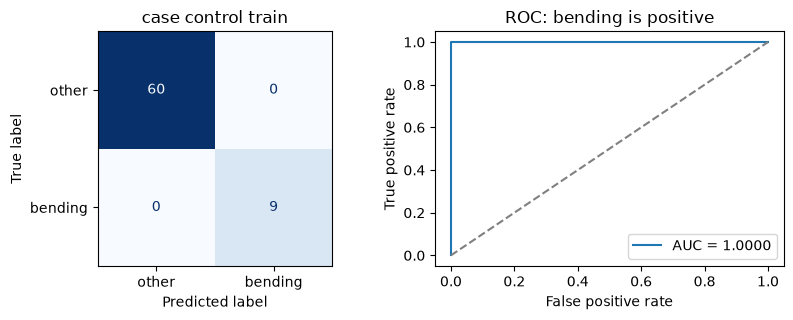

,accuracy,balanced_accuracy,auc
0,1.0000,1.0000,1.0000


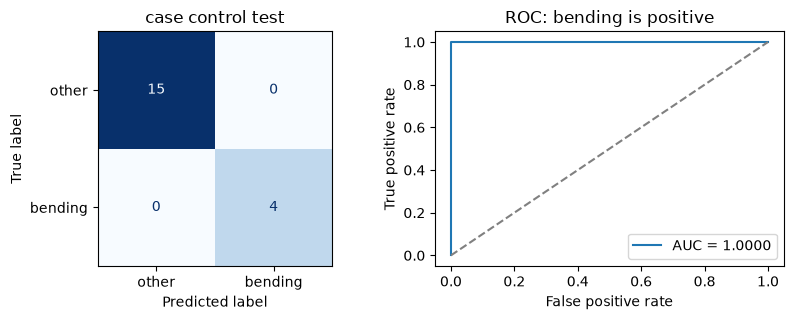

,accuracy,balanced_accuracy,auc
0,1.0000,1.0000,1.0000


The original training counts are 60 other and 9 bending. I retained all 60 other recordings and sampled 60 bending recordings with replacement. The sample prevalence is 0.5000; the target training prevalence is 0.1304. The intercept correction is logit(target) - logit(sample) = **-1.897120**. This restores the original prior odds under outcome-only sampling; slopes are unchanged by the correction. It is more than oversampling alone. The test prevalence was not used. Duplicate recordings add no independent information, and the correction does not solve separation or make probability calibration reliable.

In [8]:
rng=np.random.default_rng(SEED)
other=np.flatnonzero(y_train==0)
bending=np.flatnonzero(y_train==1)
sampled=np.r_[other,rng.choice(bending,size=len(other),replace=True)]
case_fit=LogisticRegression(C=np.inf,solver='lbfgs',max_iter=2000,tol=1e-6).fit(Z[sampled],y_train[sampled])
pi_target=y_train.mean()
pi_sample=y_train[sampled].mean()
intercept_shift=float(logit(pi_target)-logit(pi_sample))
uncorrected_intercept=float(case_fit.intercept_[0])
case_fit.intercept_ += intercept_shift
case_prob_train=case_fit.predict_proba(Z)[:,1]
Z_test=rfe_model.named_steps['select'].transform(scaler.transform(X_rfe.loc[test]))
case_prob_test=case_fit.predict_proba(Z_test)[:,1]
summary['case_control']={'target_prevalence':float(pi_target),'sample_prevalence':float(pi_sample),
    'sample_other':len(other),'sample_bending':len(other),'intercept_shift':intercept_shift,
    'uncorrected_intercept':uncorrected_intercept,'corrected_intercept':float(case_fit.intercept_[0])}
pd.DataFrame({'term':['intercept']+selected,'corrected_beta_standardized':np.r_[case_fit.intercept_,case_fit.coef_.ravel()]}).to_csv(RESULTS/'case_control_coefficients.csv',index=False)
summary['case_control']['train']=binary_evaluate(case_prob_train,y_train,'case_control_train')
summary['case_control']['test']=binary_evaluate(case_prob_test,y_test,'case_control_test')
display(Markdown(f"The original training counts are {len(other)} other and {len(bending)} bending. "
                 f"I retained all {len(other)} other recordings and sampled {len(other)} bending recordings with replacement. "
                 f"The sample prevalence is {pi_sample:.4f}; the target training prevalence is {pi_target:.4f}. "
                 f"The intercept correction is logit(target) - logit(sample) = **{intercept_shift:.6f}**. "
                 "This restores the original prior odds under outcome-only sampling; slopes are unchanged by the correction. "
                 "It is more than oversampling alone. The test prevalence was not used. Duplicate recordings add no independent "
                 "information, and the correction does not solve separation or make probability calibration reliable."))

The corrected case-control model has train and test accuracy 1.0000 and AUC 1.0000, the same as ordinary RFE here. The confusion matrices are unchanged: 60/9 correct training cases and 15/4 correct test cases. Sampling does not improve an already perfect classification result, and it does not remove separation.

### 2(b) Binary classification using L1-penalized logistic regression
#### 2(b)(i) Select l and C
For l = 1,...,20 and C = 0.01, 0.1, 1, 10, 100, 1000, I use the same five binary folds. A StandardScaler and L1 logistic model are fitted within every fitting fold. Liblinear is used for this binary model. Smaller C means stronger regularization. Features whose final coefficients have absolute value above 1e-8 are listed below; the full selected-feature table is saved as a CSV.

,l,model__C,mean_cv,std_cv,fold_1,fold_2,fold_3,fold_4,fold_5
0,11,1.0000,0.9857,0.0286,1.0000,1.0000,0.9286,1.0000,1.0000
1,12,1.0000,0.9857,0.0286,1.0000,1.0000,0.9286,1.0000,1.0000
2,18,10.0000,0.9857,0.0286,1.0000,1.0000,0.9286,1.0000,1.0000
3,19,100.0000,0.9857,0.0286,1.0000,1.0000,0.9286,1.0000,1.0000
4,1,1.0000,0.9714,0.0350,1.0000,0.9286,1.0000,0.9286,1.0000
5,12,10.0000,0.9714,0.0571,1.0000,1.0000,0.8571,1.0000,1.0000
6,13,1.0000,0.9714,0.0350,1.0000,1.0000,0.9286,0.9286,1.0000
7,18,1.0000,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000
8,18,100.0000,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000
9,19,1.0000,0.9714,0.0350,1.0000,0.9286,0.9286,1.0000,1.0000


Best **l=11**, parameters `{'model__C': np.float64(1.0)}`, CV accuracy **0.9857**. Convergence warnings: 0 during CV; 0 in the final refit.

,feature,beta_standardized
29,max_s5_p1,0.2544
73,median_s5_p2,0.5809
75,q1_s5_p2,1.3110
211,max_s1_p6,-0.7862
318,median_s4_p8,-0.3091
375,std_s6_p9,-0.1466
406,min_s5_p10,0.7211
414,max_s6_p10,-0.0343


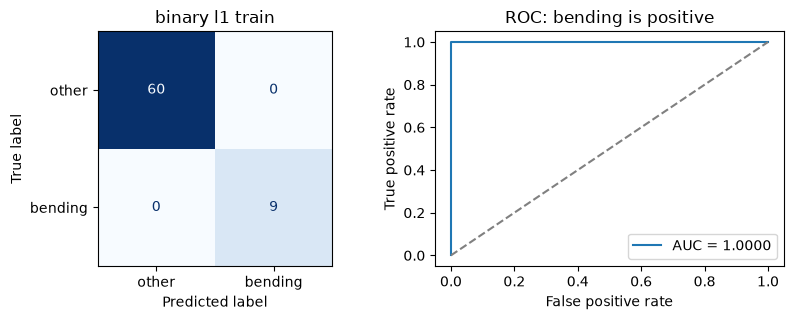

,accuracy,balanced_accuracy,auc
0,1.0000,1.0000,1.0000


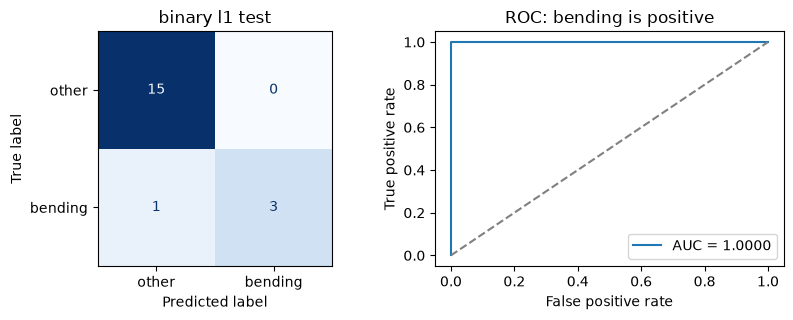

,accuracy,balanced_accuracy,auc
0,0.9474,0.8750,1.0000


,method,l,selected_features,cv_accuracy,test_accuracy,test_balanced_accuracy,test_auc
0,Unpenalized + RFE,1,4,0.9857,1.0000,1.0000,1.0000
1,L1 logistic,11,8,0.9857,0.9474,0.8750,1.0000


In [9]:
C_GRID=[.01,.1,1,10,100,1000]
l1_pipeline=Pipeline([('scale',StandardScaler()),
                       ('model',LogisticRegression(l1_ratio=1,solver='liblinear',random_state=SEED,
                                                   max_iter=5000,tol=1e-5))])
l1_model,l1_cv=search_segments(l1_pipeline,{'model__C':C_GRID},y_train,cv_binary,'binary_l1')
l_l1=summary['binary_l1']['l']
l1_coef=l1_model.named_steps['model'].coef_.ravel()
l1_selected=pd.DataFrame({'feature':features[l_l1].columns,'beta_standardized':l1_coef})
l1_selected=l1_selected[np.abs(l1_selected.beta_standardized)>1e-8]
l1_selected.to_csv(RESULTS/'binary_l1_selected_features.csv',index=False)
summary['binary_l1']['nonzero_features']=len(l1_selected)
display(l1_selected)
summary['binary_l1']['train']=binary_evaluate(l1_model.predict_proba(features[l_l1].loc[train])[:,1],y_train,'binary_l1_train')
summary['binary_l1']['test']=binary_evaluate(l1_model.predict_proba(features[l_l1].loc[test])[:,1],y_test,'binary_l1_test')
binary_comparison=pd.DataFrame([{'method':name,'l':summary[key]['l'],
    'selected_features':len(selected) if key=='rfe' else len(l1_selected),
    'cv_accuracy':summary[key]['cv_accuracy'],'test_accuracy':summary[key]['test']['accuracy'],
    'test_balanced_accuracy':summary[key]['test']['balanced_accuracy'],'test_auc':summary[key]['test']['auc']}
    for name,key in [('Unpenalized + RFE','rfe'),('L1 logistic','binary_l1')]])
binary_comparison.to_csv(RESULTS/'binary_comparison.csv',index=False)
display(binary_comparison)

#### 2(b)(ii) L1 and the permitted RFE alternative
Question 2(a)(iii) explicitly permits RFE instead of p-value pruning. I used that alternative because the ordinary logistic fit has complete separation, so its Wald p-values are invalid. Question 2(b)(ii) specifically names p-value-based selection; **the measured comparison here is RFE vs L1, not a separate p-value-selected baseline**.

P-value-based selection tests coefficients and removes terms using a significance cutoff. RFE instead ranks coefficient importance and chooses the retained feature count by CV; its ranks are not p-values. L1 selects features while shrinking coefficients. Screening with the invalid Wald p-values would not give a defensible p-value baseline. The supplementary Firth tests describe the already selected model; they were not used for feature selection and are not selection-adjusted.

Both models have CV accuracy 0.9857. Ordinary RFE has test accuracy 1.0000, versus 0.9474 for L1; L1 misses one of four bending cases. Both test AUCs are 1.0000, so ranking is perfect even though L1's 0.5 threshold misses a case. RFE performs better on this split; L1 is easier to implement and gives finite, sparse coefficients. These results do not establish whether a separate p-value-based procedure would perform better, and the small, partly duplicated test set does not establish a universal ranking.

### 2(c) Multiclass classification
#### 2(c)(i) L1 multinomial logistic regression
The response now has all seven activity labels. The `saga` solver optimizes the joint multinomial loss with an L1 penalty, rather than fitting seven unrelated binary classifiers. I search l = 1,...,20 and C = 0.01, 0.1, 1, 10, 100, 1000. Standardization is fitted within each CV fitting fold.

I use **five stratified folds** for all multiclass methods, matching the assignment's binary CV procedure. Bending2 has only four training recordings, so one validation fold has no bending2 example. Every fitting fold still contains all seven classes. Accuracy is defined for every fold; I do not calculate fold-level multiclass ROC. The saved fold-count table documents the rare class. Final ROC is evaluated on the test set, which contains every class.

For the test confusion matrix, rows are true activities and columns predicted activities. For ROC, each activity is the positive class against all others (one-vs-rest). The macro AUC is the unweighted mean of seven per-class AUCs; the weighted AUC weights each by its test support. Every class has test positives and negatives, so all seven curves can be computed. The final test classification error is 1 minus accuracy.

,l,model__C,mean_cv,std_cv,fold_1,fold_2,fold_3,fold_4,fold_5
0,2,1000.0000,0.9429,0.0286,0.9286,0.9286,0.9286,0.9286,1.0000
1,2,100.0000,0.9286,0.0452,0.9286,0.8571,0.9286,0.9286,1.0000
2,1,10.0000,0.9132,0.0281,0.8571,0.9286,0.9286,0.9286,0.9231
3,1,100.0000,0.9132,0.0532,0.8571,0.9286,1.0000,0.8571,0.9231
4,1,1000.0000,0.9132,0.0532,0.8571,0.9286,1.0000,0.8571,0.9231
5,2,10.0000,0.9000,0.0728,0.9286,0.7857,0.8571,0.9286,1.0000
6,4,100.0000,0.8989,0.0342,0.9286,0.8571,0.9286,0.8571,0.9231
7,4,1000.0000,0.8989,0.0342,0.9286,0.8571,0.9286,0.8571,0.9231
8,6,100.0000,0.8989,0.0342,0.9286,0.8571,0.8571,0.9286,0.9231
9,6,1000.0000,0.8989,0.0342,0.9286,0.8571,0.8571,0.9286,0.9231


Best **l=2**, parameters `{'model__C': np.float64(1000.0)}`, CV accuracy **0.9429**. Convergence warnings: 0 during CV; 0 in the final refit.

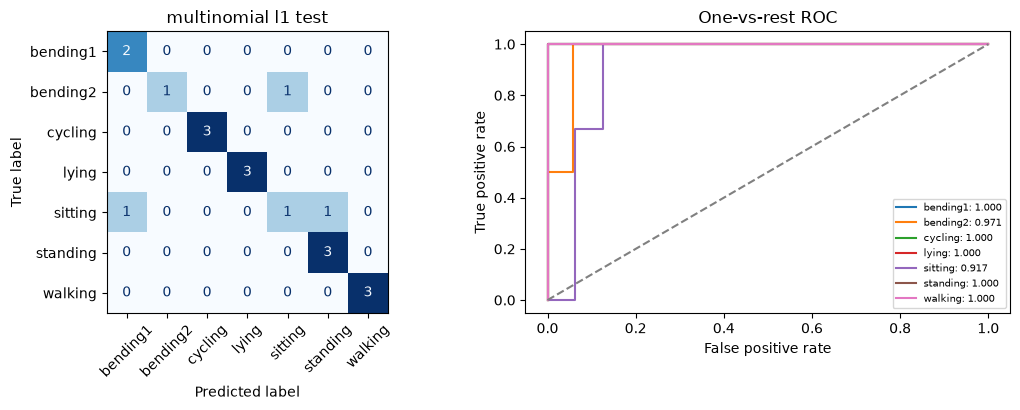

,accuracy,error_rate,macro_auc,weighted_auc
0,0.8421,0.1579,0.9839,0.9837


,class,test_support,ovr_auc
0,bending1,2,1.0000
1,bending2,2,0.9706
2,cycling,3,1.0000
3,lying,3,1.0000
4,sitting,3,0.9167
5,standing,3,1.0000
6,walking,3,1.0000


In [10]:
def multiclass_evaluate(model,l,name):
    probability=model.predict_proba(features[l].loc[test])
    predicted=model.predict(features[l].loc[test])
    labels=model.named_steps['model'].classes_
    cm=confusion_matrix(y_multi_test,predicted,labels=labels)
    indicators=label_binarize(y_multi_test,classes=labels)
    per_auc=np.array([roc_auc_score(indicators[:,k],probability[:,k]) for k in range(len(labels))])
    support=indicators.sum(axis=0)
    metrics={'accuracy':float(accuracy_score(y_multi_test,predicted)),
             'error_rate':float(1-accuracy_score(y_multi_test,predicted)),
             'macro_auc':float(per_auc.mean()),'weighted_auc':float(np.average(per_auc,weights=support)),
             'confusion_matrix':cm.tolist()}
    auc_table=pd.DataFrame({'class':labels,'test_support':support,'ovr_auc':per_auc})
    auc_table.to_csv(RESULTS/f'{name}_auc.csv',index=False)
    pd.DataFrame(probability,columns=labels).assign(true=y_multi_test,predicted=predicted).to_csv(RESULTS/f'{name}_predictions.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(11,4.2))
    ConfusionMatrixDisplay(cm,display_labels=labels).plot(ax=axes[0],colorbar=False,cmap='Blues',xticks_rotation=45)
    axes[0].set_title(name.replace('_',' '))
    for k,label in enumerate(labels):
        fpr,tpr,_=roc_curve(indicators[:,k],probability[:,k])
        axes[1].plot(fpr,tpr,label=f'{label}: {per_auc[k]:.3f}')
    axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='One-vs-rest ROC')
    axes[1].legend(fontsize=7,loc='lower right')
    fig.tight_layout();fig.savefig(RESULTS/f'{name}.png',dpi=180)
    plt.show();plt.close(fig)
    display(pd.DataFrame([{k:v for k,v in metrics.items() if k!='confusion_matrix'}]))
    display(auc_table)
    return metrics

multi_pipeline=Pipeline([('scale',StandardScaler()),
    ('model',LogisticRegression(l1_ratio=1,solver='saga',random_state=SEED,max_iter=10000,tol=1e-3))])
multi_model,multi_cv=search_segments(multi_pipeline,{'model__C':[.01,.1,1,10,100,1000]},y_multi_train,cv_multi,'multinomial_l1')
l_multi=summary['multinomial_l1']['l']
summary['multinomial_l1']['test']=multiclass_evaluate(multi_model,l_multi,'multinomial_l1_test')
coefs=pd.DataFrame(multi_model.named_steps['model'].coef_,index=classes,columns=features[l_multi].columns)
coefs.to_csv(RESULTS/'multinomial_l1_coefficients.csv')
summary['multinomial_l1']['nonzero_features']=int((np.abs(coefs)>1e-8).any(axis=0).sum())

#### 2(c)(ii) Gaussian and Multinomial Naive Bayes
Both models search every l = 1,...,20 using the same five multiclass folds. GaussianNB also searches variance smoothing in {1e-9, 1e-6, 1e-3, 0.1, 1}; its within-fold StandardScaler keeps the smoothing comparison from being dominated by channel units. It assumes independent Gaussian feature values given the class.

MultinomialNB searches alpha in {0.001, 0.01, 0.1, 1, 10}. Every extracted statistic is nonnegative in this dataset. A within-fold MaxAbsScaler rescales columns without making validation or test values negative; it does not subtract a minimum or use test statistics. A transformed test value may exceed one, which is allowed. These continuous summaries are not event counts, so the multinomial likelihood is an approximation. Their strong correlations also violate the conditional-independence assumption. The experiment is still included as requested, and its actual performance determines the comparison.

,l,model__var_smoothing,mean_cv,std_cv,fold_1,fold_2,fold_3,fold_4,fold_5
0,8,0.1000,0.8978,0.0378,0.9286,0.9286,0.8571,0.9286,0.8462
1,1,0.1000,0.8967,0.0781,0.8571,0.9286,1.0000,0.9286,0.7692
2,1,0.0010,0.8846,0.0852,0.7143,0.9286,0.9286,0.9286,0.9231
3,2,0.0010,0.8846,0.0564,0.7857,0.8571,0.9286,0.9286,0.9231
4,5,0.1000,0.8835,0.0370,0.9286,0.9286,0.8571,0.8571,0.8462
5,2,0.1000,0.8824,0.0630,0.9286,0.8571,0.9286,0.9286,0.7692
6,1,0.0000,0.8692,0.0542,0.7857,0.8571,0.9286,0.9286,0.8462
7,1,0.0000,0.8692,0.0838,0.7143,0.9286,0.9286,0.9286,0.8462
8,7,0.1000,0.8692,0.0542,0.8571,0.9286,0.7857,0.9286,0.8462
9,6,0.1000,0.8681,0.0869,0.7857,0.9286,0.8571,1.0000,0.7692


Best **l=8**, parameters `{'model__var_smoothing': np.float64(0.1)}`, CV accuracy **0.8978**. Convergence warnings: 0 during CV; 0 in the final refit.

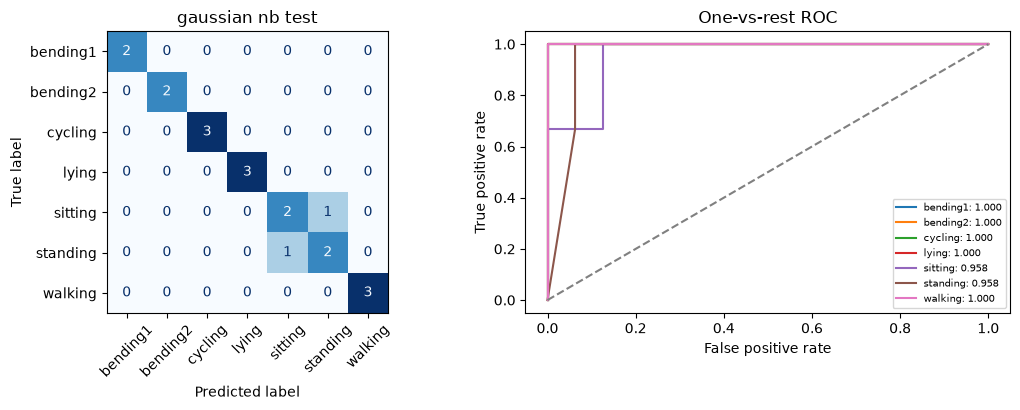

,accuracy,error_rate,macro_auc,weighted_auc
0,0.8947,0.1053,0.9881,0.9868


,class,test_support,ovr_auc
0,bending1,2,1.0000
1,bending2,2,1.0000
2,cycling,3,1.0000
3,lying,3,1.0000
4,sitting,3,0.9583
5,standing,3,0.9583
6,walking,3,1.0000


,l,model__alpha,mean_cv,std_cv,fold_1,fold_2,fold_3,fold_4,fold_5
0,10,0.1000,0.8110,0.0591,0.7857,0.9286,0.7857,0.7857,0.7692
1,20,0.1000,0.8110,0.0744,0.7143,0.9286,0.7857,0.8571,0.7692
2,17,0.0010,0.7967,0.0710,0.7143,0.9286,0.7857,0.7857,0.7692
3,14,0.0100,0.7956,0.0881,0.7143,0.9286,0.7857,0.8571,0.6923
4,14,0.1000,0.7945,0.1134,0.7143,0.9286,0.8571,0.8571,0.6154
5,5,0.1000,0.7824,0.0457,0.7857,0.7857,0.8571,0.7143,0.7692
6,17,0.0100,0.7824,0.0785,0.7143,0.9286,0.7143,0.7857,0.7692
7,18,0.0010,0.7824,0.0785,0.7143,0.9286,0.7143,0.7857,0.7692
8,18,0.0100,0.7824,0.0785,0.7143,0.9286,0.7143,0.7857,0.7692
9,19,0.0100,0.7824,0.0906,0.6429,0.9286,0.7857,0.7857,0.7692


Best **l=10**, parameters `{'model__alpha': np.float64(0.1)}`, CV accuracy **0.8110**. Convergence warnings: 0 during CV; 0 in the final refit.

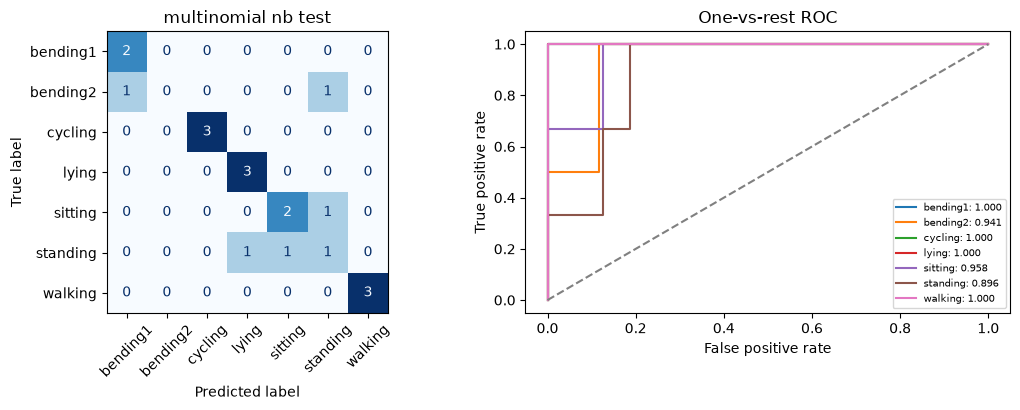

,accuracy,error_rate,macro_auc,weighted_auc
0,0.7368,0.2632,0.9708,0.9708


,class,test_support,ovr_auc
0,bending1,2,1.0000
1,bending2,2,0.9412
2,cycling,3,1.0000
3,lying,3,1.0000
4,sitting,3,0.9583
5,standing,3,0.8958
6,walking,3,1.0000


,method,l,cv_accuracy,accuracy,error_rate,macro_auc,weighted_auc
0,multinomial_l1,2,0.9429,0.8421,0.1579,0.9839,0.9837
1,gaussian_nb,8,0.8978,0.8947,0.1053,0.9881,0.9868
2,multinomial_nb,10,0.8110,0.7368,0.2632,0.9708,0.9708


In [11]:
gaussian_pipeline=Pipeline([('scale',StandardScaler()),('model',GaussianNB())])
gaussian_model,gaussian_cv=search_segments(gaussian_pipeline,{'model__var_smoothing':[1e-9,1e-6,1e-3,.1,1]},y_multi_train,cv_multi,'gaussian_nb')
l_gaussian=summary['gaussian_nb']['l']
summary['gaussian_nb']['test']=multiclass_evaluate(gaussian_model,l_gaussian,'gaussian_nb_test')
assert all((frame.to_numpy()>=0).all() for frame in features.values())
multinomial_pipeline=Pipeline([('scale',MaxAbsScaler()),('model',MultinomialNB())])
nb_model,nb_cv=search_segments(multinomial_pipeline,{'model__alpha':[.001,.01,.1,1,10]},y_multi_train,cv_multi,'multinomial_nb')
l_nb=summary['multinomial_nb']['l']
summary['multinomial_nb']['test']=multiclass_evaluate(nb_model,l_nb,'multinomial_nb_test')
assert (nb_model.named_steps['scale'].transform(features[l_nb].loc[test])>=0).all()
comparison=pd.DataFrame([{'method':key,'l':summary[key]['l'],'cv_accuracy':summary[key]['cv_accuracy'],
                         **{k:v for k,v in summary[key]['test'].items() if k!='confusion_matrix'}}
    for key in ['multinomial_l1','gaussian_nb','multinomial_nb']])
comparison.to_csv(RESULTS/'multiclass_comparison.csv',index=False)
display(comparison)

#### 2(c)(iii) Compare the multiclass models
The table above compares the same held-out recordings and the same multiclass CV folds. The conclusion below distinguishes the CV winner from the test winner and uses the confusion matrices to identify errors. With only 19 test recordings, a one-recording difference changes accuracy by 5.26 percentage points; it should not be treated as proof that a model is universally best.

L1 multinomial logistic has the highest selected CV accuracy (0.9429), compared with GaussianNB (0.8978) and MultinomialNB (0.8110). GaussianNB has the best observed test accuracy (0.8947), followed by multinomial logistic (0.8421) and MultinomialNB (0.7368). Thus CV would select multinomial logistic before looking at the test set, but GaussianNB is best on this held-out split. Gaussian smoothing can help with few examples; the multinomial count assumption fits continuous, correlated summaries less well. The difference between the CV and test rankings illustrates the uncertainty from small class samples.

**multinomial_l1 errors:** bending2 classified as sitting: 1; sitting classified as bending1: 1; sitting classified as standing: 1.

**gaussian_nb errors:** sitting classified as standing: 1; standing classified as sitting: 1.

**multinomial_nb errors:** bending2 classified as bending1: 1; bending2 classified as standing: 1; sitting classified as standing: 1; standing classified as lying: 1; standing classified as sitting: 1.

## 3. ISLR 4.8.3: quadratic Bayes rule
The exact exercise in the supplied textbook (printed p.193, PDF p.202) assumes one feature and K classes, with $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$. It asks why the Bayes decision rule is quadratic when class variances may differ.

Let $\pi_k=P(Y=k)$. Bayes' rule assigns x to the class maximizing
$$P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_j\pi_j f_j(x)}.$$
The denominator is the same for every class. Taking the logarithm, dropping only the common $-\tfrac12\log(2\pi)$, and expanding gives
$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}$$
$$=-\frac{1}{2\sigma_k^2}x^2+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}+\log\pi_k-\log\sigma_k.$$
For classes k and j, the boundary solves $\delta_k(x)-\delta_j(x)=0$. The coefficient of $x^2$ is
$$\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.$$
It generally does not cancel when the class variances differ. Thus the discriminant comparison is quadratic, not generally linear. In one dimension there can be two crossing points rather than one. If variances happen to be equal, the quadratic terms cancel and the rule reduces to a linear comparison; QDA allows but does not force a nonlinear boundary in every special case.

## 4. ISLR 4.8.7: dividend probability
The exact exercise (printed p.195, PDF p.204) gives $\mu_{Yes}=10$, $\mu_{No}=0$, a common variance $\sigma^2=36$, and priors $\pi_{Yes}=0.8$, $\pi_{No}=0.2$. For last year's percentage profit x = 4,
$$f_{Yes}(4)=\frac{1}{6\sqrt{2\pi}}\exp\left[-\frac{(4-10)^2}{72}\right],\qquad
f_{No}(4)=\frac{1}{6\sqrt{2\pi}}\exp\left[-\frac{(4-0)^2}{72}\right].$$
Bayes' rule gives
$$P(Yes\mid X=4)=\frac{0.8f_{Yes}(4)}{0.8f_{Yes}(4)+0.2f_{No}(4)}
=\frac{1}{1+0.25e^{5/18}}.$$
The density ratio is $f_{No}(4)/f_{Yes}(4)=\exp[(36-16)/72]=e^{5/18}$. The common normal-density constant cancels. The following calculation evaluates the densities and posterior without rounding intermediate values.

In [12]:
prior_yes,prior_no=.8,.2
likelihood_yes=norm.pdf(4,loc=10,scale=6)
likelihood_no=norm.pdf(4,loc=0,scale=6)
posterior=prior_yes*likelihood_yes/(prior_yes*likelihood_yes+prior_no*likelihood_no)
book7=pd.DataFrame([{'prior_yes':prior_yes,'prior_no':prior_no,'density_yes_at4':likelihood_yes,
                     'density_no_at4':likelihood_no,'posterior_yes':posterior}])
book7.to_csv(RESULTS/'islr_4_8_7.csv',index=False)
display(book7)
summary['islr_4_8_7']={'posterior_yes':float(posterior),'density_yes':float(likelihood_yes),'density_no':float(likelihood_no)}
# Save only numeric summaries, not fitted models or intermediate cache files.
with (RESULTS/'summary.json').open('w') as stream:
    json.dump(summary,stream,indent=2)

,prior_yes,prior_no,density_yes_at4,density_no_at4,posterior_yes
0,0.8000,0.2000,0.0403,0.0532,0.7519


The estimated probability is **0.75185245**, or about **75.19%**. The predicted class at a 0.5 threshold is **Yes**. Profit 4 is closer to the non-dividend mean, but the much larger dividend prior makes Yes more likely.

## References and AI assistance
- Supplied Homework4.pdf, Questions 2-4; supplied textbook, printed pp.193 and 195.
- [Scikit-learn logistic regression](https://scikit-learn.org/1.8/modules/linear_model.html#logistic-regression), [cross-validation](https://scikit-learn.org/1.8/modules/cross_validation.html), and [Naive Bayes](https://scikit-learn.org/1.8/modules/naive_bayes.html).
- [Firth (1993), Bias reduction of maximum likelihood estimates](https://doi.org/10.1093/biomet/80.1.27); [logistf documentation](https://search.r-project.org/CRAN/refmans/logistf/html/logistf-package.html): Jeffreys-information penalty and penalized likelihood-ratio inference, used only as a supplement here.

AI tools assisted with chapter concepts, unfamiliar code, and preparing code and explanations.